# Import

In [3]:
import torch
from torch import nn
from torchvision import models, transforms, datasets
import time

# Load Dataset trainval and test

In [4]:
DATA_PATH = "./data"

trainval_data = datasets.OxfordIIITPet(root=DATA_PATH, split='trainval', download=True)
test_data = datasets.OxfordIIITPet(root=DATA_PATH, split='test', download=True)

100%|██████████| 792M/792M [00:31<00:00, 25.5MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.6MB/s]


In [5]:
print("Trainval pictures:", len(trainval_data))
print("Official test pictures:", len(test_data))

Trainval pictures: 3680
Official test pictures: 3669


# Select only 10 breed (5 cat and 5 dog seperately)

In [6]:
trainval_data.classes

['Abyssinian',
 'American Bulldog',
 'American Pit Bull Terrier',
 'Basset Hound',
 'Beagle',
 'Bengal',
 'Birman',
 'Bombay',
 'Boxer',
 'British Shorthair',
 'Chihuahua',
 'Egyptian Mau',
 'English Cocker Spaniel',
 'English Setter',
 'German Shorthaired',
 'Great Pyrenees',
 'Havanese',
 'Japanese Chin',
 'Keeshond',
 'Leonberger',
 'Maine Coon',
 'Miniature Pinscher',
 'Newfoundland',
 'Persian',
 'Pomeranian',
 'Pug',
 'Ragdoll',
 'Russian Blue',
 'Saint Bernard',
 'Samoyed',
 'Scottish Terrier',
 'Shiba Inu',
 'Siamese',
 'Sphynx',
 'Staffordshire Bull Terrier',
 'Wheaten Terrier',
 'Yorkshire Terrier']

In [7]:
selected_breeds = [   # 5 cats and 5 dogs
  "Abyssinian",
  "Bengal",
  "Birman",
  "Bombay",
  "British Shorthair",
  "American Bulldog",
  "Basset Hound",
  "Beagle",
  "Boxer",
  "Chihuahua",
]

In [8]:
selected_breed_ids = [trainval_data.class_to_idx[breed] for breed in selected_breeds]

list(zip(selected_breeds, selected_breed_ids))

[('Abyssinian', 0),
 ('Bengal', 5),
 ('Birman', 6),
 ('Bombay', 7),
 ('British Shorthair', 9),
 ('American Bulldog', 1),
 ('Basset Hound', 3),
 ('Beagle', 4),
 ('Boxer', 8),
 ('Chihuahua', 10)]

### Update the index to be sorted

In [9]:
original_to_new_label = {
    old_label: new_label
    for new_label, old_label in enumerate(selected_breed_ids)
}

print(original_to_new_label)
list(zip(selected_breeds, original_to_new_label.values()))

{0: 0, 5: 1, 6: 2, 7: 3, 9: 4, 1: 5, 3: 6, 4: 7, 8: 8, 10: 9}


[('Abyssinian', 0),
 ('Bengal', 1),
 ('Birman', 2),
 ('Bombay', 3),
 ('British Shorthair', 4),
 ('American Bulldog', 5),
 ('Basset Hound', 6),
 ('Beagle', 7),
 ('Boxer', 8),
 ('Chihuahua', 9)]

# Combining the two original dataset (trainval and test)

In [10]:
from torch.utils.data import ConcatDataset
from collections import Counter

all_data = ConcatDataset([trainval_data, test_data])
all_original_labels = trainval_data._labels + test_data._labels # _labels = dataset's original indexes/indices

selected_indices = [i for i, old_label in enumerate(all_original_labels) if old_label in original_to_new_label] # find similarity with the old_label
selected_labels = [original_to_new_label[all_original_labels[i]] for i in selected_indices] # array of new_label picture (there's more than 1 of the same new_label type)

print("Pictures from selected breeds:", len(selected_indices))
print("Pictures per selected breed:", Counter(selected_labels))

Pictures from selected breeds: 1981
Pictures per selected breed: Counter({5: 200, 6: 200, 7: 200, 1: 200, 2: 200, 4: 200, 9: 200, 8: 199, 0: 198, 3: 184})


# Splitting pictures data / Dataset Splitting (70/15/15)

In [11]:
from sklearn.model_selection import train_test_split

train_indices, temp_indices, train_labels, temp_labels = train_test_split(
    selected_indices,
    selected_labels,
    test_size=0.30,
    random_state=42,
    stratify=selected_labels,
)

val_indices, test_indices, val_labels, test_labels = train_test_split(
    temp_indices,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels,
)

print("Train:", len(train_indices), Counter(train_labels))
print("Validation:", len(val_indices), Counter(val_labels))
print("Test:", len(test_indices), Counter(test_labels))

Train: 1386 Counter({2: 140, 5: 140, 4: 140, 7: 140, 6: 140, 9: 140, 1: 140, 8: 139, 0: 138, 3: 129})
Validation: 297 Counter({1: 30, 2: 30, 9: 30, 4: 30, 0: 30, 7: 30, 5: 30, 8: 30, 6: 30, 3: 27})
Test: 298 Counter({1: 30, 5: 30, 7: 30, 4: 30, 2: 30, 6: 30, 8: 30, 0: 30, 9: 30, 3: 28})


# **Preparation before running the 5 given Experiment from the Question**

In [12]:
from torch.utils.data import Dataset

class SelectedPetDataset(Dataset):
    # Constructor (for attributes)
    def __init__(self, base_data, indices, label_map, transform):
        self.base_data = base_data  # all the pictures from the original dataset collections.
        self.indices = indices      # the positions of the pictures selected for this group—train, validation, or test.
        self.label_map = label_map  # the table that changes the original breed numbers into our new numbers, 0–9.
        self.transform = transform  # the picture-preparation steps for this group.

    # Method to indicate how many picture is selected for training
    def __len__(self):
        return len(self.indices)

    # Method to fetch one picture of a certain "position", applies its image transform, and changes its old breed number to the new 0–9 number.
    def __getitem__(self, position):
        original_index = self.indices[position]
        image, old_label = self.base_data[original_index]

        image = self.transform(image)
        new_label = self.label_map[old_label]

        return image, new_label

### Pipeline Transformasi Data

In [13]:
# Inisialisasi Model & Ekstraksi Bobot Pretrained
weights = models.ResNet18_Weights.IMAGENET1K_V1

eval_transforms = weights.transforms()
train_transforms = weights.transforms()

### Pictures Data (not indexes)

In [14]:
train_data = SelectedPetDataset(all_data, train_indices, original_to_new_label, train_transforms)
val_data = SelectedPetDataset(all_data, val_indices, original_to_new_label, eval_transforms)
test_data = SelectedPetDataset(all_data, test_indices, original_to_new_label, eval_transforms)

print("Training pictures: ", len(train_data))
print("Evaluation pictures: ", len(val_data))
print("Test pictures: ", len(test_data))

Training pictures:  1386
Evaluation pictures:  297
Test pictures:  298


In [15]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape, "\n")

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32]) 



### Preparing a Training Process Loop

In [16]:
MAX_EPOCHS = 30
PATIENCE = 4
criterion = nn.CrossEntropyLoss()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [17]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        scores = model(images)
        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)

In [18]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            scores = model(images)
            loss = criterion(scores, labels)

            total_loss += loss.item() * images.size(0)
            predictions = scores.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total
    return average_loss, accuracy

In [19]:
import random
import numpy as np
import copy

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

### Result Save Point of all Experiments

In [20]:
all_histories = {}
summary_rows = []

# B1 - Baseline From Scratch

Latih ResNet-18 dari inisialisasi acak (weights=None) pada 10 kelas. Kondisi ini menjadi tolok ukur batas bawah (baseline) efektivitas representasi pretrained.

In [21]:
set_seed(42)

model = models.resnet18(weights=None)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)
model = model.to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-2,)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
optimizer.param_groups[0]["name"] = "fc"
learning_rate = "; ".join(f"{group['name']}={group['lr']}" for group in optimizer.param_groups)

print(f"B1 Trainable Parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")

B1 Trainable Parameters: 11,181,642 / 11,181,642
Learning rate: fc=0.001


In [22]:
experiment_name = "B1"
history_b1 = []

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

    print(
        f"Epoch {epoch}: "
        f"train loss={train_loss:.3f}, "
        f"validation loss={val_loss:.3f}, "
        f"validation accuracy={val_accuracy:.1%}"
    )

    history_b1.append({
        "experiment": experiment_name,
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        epochs_without_improvement = 0
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Stopping: validation loss stopped improving.")
        break

if best_model_state is not None:
    model.load_state_dict(best_model_state)

epochs_run = epoch
training_minutes = (time.perf_counter() - training_start) / 60
all_histories[experiment_name] = history_b1
torch.save(model.state_dict(), "B1_best.pth")

print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")

Epoch 1: train loss=2.218, validation loss=2.761, validation accuracy=20.9%
Epoch 2: train loss=1.855, validation loss=2.340, validation accuracy=33.3%
Epoch 3: train loss=1.708, validation loss=1.958, validation accuracy=39.4%
Epoch 4: train loss=1.579, validation loss=2.878, validation accuracy=23.6%
Epoch 5: train loss=1.519, validation loss=2.028, validation accuracy=34.0%
Epoch 6: train loss=1.380, validation loss=1.619, validation accuracy=42.4%
Epoch 7: train loss=1.263, validation loss=1.744, validation accuracy=40.7%
Epoch 8: train loss=1.195, validation loss=1.679, validation accuracy=42.4%
Epoch 9: train loss=1.108, validation loss=1.604, validation accuracy=45.8%
Epoch 10: train loss=1.043, validation loss=1.821, validation accuracy=45.8%
Epoch 11: train loss=0.879, validation loss=2.799, validation accuracy=38.4%
Epoch 12: train loss=0.802, validation loss=2.484, validation accuracy=38.7%
Epoch 13: train loss=0.787, validation loss=2.165, validation accuracy=44.1%
Stopping

In [23]:
_, train_accuracy = evaluate(model, train_loader, criterion, device)
_, val_accuracy = evaluate(model, val_loader, criterion, device)
test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)

print(f"Train accuracy: {train_accuracy:.1%}")
print(f"Validation accuracy: {val_accuracy:.1%}")
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test loss: {test_loss:.3f}")

Train accuracy: 62.3%
Validation accuracy: 45.8%
Test accuracy: 43.6%
Test loss: 1.839


In [24]:
from sklearn.metrics import f1_score

all_labels = []
all_predictions = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        scores = model(images)
        predictions = scores.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())

macro_f1 = f1_score(all_labels, all_predictions, average="macro")
print(f"B1 Test Macro F1: {macro_f1:.3f}")

B1 Test Macro F1: 0.421


In [25]:
summary_rows.append({
    "experiment": experiment_name,
    "trainable_parameters": trainable_params,
    "learning_rate": learning_rate,
    "epochs_run": epochs_run,
    "best_epoch": best_epoch,
    "training_minutes": training_minutes,
    "best_validation_accuracy": best_val_accuracy,
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "test_macro_f1": macro_f1,
})

print("B1 summary")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")
print(f"Epochs run: {epochs_run}")
print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")
print(f"Best validation accuracy: {best_val_accuracy:.1%}")
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test loss: {test_loss:.3f}")
print(f"B1 Test Macro F1: {macro_f1:.3f}")

B1 summary
Trainable parameters: 11,181,642 / 11,181,642
Learning rate: fc=0.001
Epochs run: 13
Best epoch: 9
Training duration: 3.38 minutes
Best validation accuracy: 45.8%
Test accuracy: 43.6%
Test loss: 1.839
B1 Test Macro F1: 0.421


# B2 - Feature Extraction

Gunakan ResNet-18 pretrained, bekukan seluruh lapisan backbone (requires_grad = False), ganti layer model.fc dengan linear head baru (nn.Linear(512, 10)), dan latih hanya bagian classifier head.

In [26]:
set_seed(42)

model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)
model = model.to(device)

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2,)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
optimizer.param_groups[0]["name"] = "fc"
learning_rate = "; ".join(f"{group['name']}={group['lr']}" for group in optimizer.param_groups)

print(f"B2 Trainable Parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s]


B2 Trainable Parameters: 5,130 / 11,181,642
Learning rate: fc=0.001


In [27]:
experiment_name = "B2"
history_b2 = []

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    print(
        f"Epoch {epoch}: "
        f"train loss={train_loss:.3f}, "
        f"validation loss={val_loss:.3f}, "
        f"validation accuracy={val_accuracy:.1%}"
    )

    history_b2.append({
        "experiment": experiment_name,
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        epochs_without_improvement = 0
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Stopping: validation loss stopped improving.")
        break

if best_model_state is not None:
    model.load_state_dict(best_model_state)

epochs_run = epoch
training_minutes = (time.perf_counter() - training_start) / 60
all_histories[experiment_name] = history_b2
torch.save(model.state_dict(), "B2_best.pth")

print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")

Epoch 1: train loss=1.303, validation loss=0.613, validation accuracy=90.6%
Epoch 2: train loss=0.519, validation loss=0.360, validation accuracy=95.3%
Epoch 3: train loss=0.357, validation loss=0.295, validation accuracy=93.6%
Epoch 4: train loss=0.291, validation loss=0.259, validation accuracy=94.9%
Epoch 5: train loss=0.259, validation loss=0.242, validation accuracy=94.3%
Epoch 6: train loss=0.227, validation loss=0.216, validation accuracy=95.6%
Epoch 7: train loss=0.206, validation loss=0.220, validation accuracy=94.9%
Epoch 8: train loss=0.172, validation loss=0.201, validation accuracy=95.6%
Epoch 9: train loss=0.170, validation loss=0.189, validation accuracy=96.0%
Epoch 10: train loss=0.160, validation loss=0.184, validation accuracy=96.6%
Epoch 11: train loss=0.139, validation loss=0.180, validation accuracy=96.0%
Epoch 12: train loss=0.134, validation loss=0.202, validation accuracy=94.6%
Epoch 13: train loss=0.135, validation loss=0.190, validation accuracy=96.0%
Epoch 14

In [28]:
_, train_accuracy = evaluate(model, train_loader, criterion, device)
_, val_accuracy = evaluate(model, val_loader, criterion, device)
test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)

print(f"Train accuracy: {train_accuracy:.1%}")
print(f"Validation accuracy: {val_accuracy:.1%}")
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test loss: {test_loss:.3f}")

Train accuracy: 99.4%
Validation accuracy: 97.0%
Test accuracy: 94.6%
Test loss: 0.167


In [29]:
all_labels = []
all_predictions = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        scores = model(images)
        predictions = scores.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print(f"B2 Test Macro F1: {macro_f1:.3f}")

B2 Test Macro F1: 0.946


In [30]:
summary_rows.append({
    "experiment": experiment_name,
    "trainable_parameters": trainable_params,
    "learning_rate": learning_rate,
    "epochs_run": epochs_run,
    "best_epoch": best_epoch,
    "training_minutes": training_minutes,
    "best_validation_accuracy": best_val_accuracy,
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "test_macro_f1": macro_f1,
})

print("B2 summary")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")
print(f"Epochs run: {epochs_run}")
print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")
print(f"Best validation accuracy: {best_val_accuracy:.1%}")
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test loss: {test_loss:.3f}")
print(f"B2 Test Macro F1: {macro_f1:.3f}")

B2 summary
Trainable parameters: 5,130 / 11,181,642
Learning rate: fc=0.001
Epochs run: 23
Best epoch: 19
Training duration: 4.77 minutes
Best validation accuracy: 97.0%
Test accuracy: 94.6%
Test loss: 0.167
B2 Test Macro F1: 0.946


# B3 - Progressive Fine-Tuning

Mulai dari model pretrained, buka pembekuan (unfreeze) blok residual terakhir (layer4) dan lapisan fc. Terapkan differential learning rate (misalnya: lr = 1e-4 untuk layer4 dan lr = 1e-3 untuk fc).

In [31]:
set_seed(42)

model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 10)

for param in model.layer4.parameters():
    param.requires_grad = True

model = model.to(device)

optimizer = torch.optim.AdamW(
    [
        {"params": model.layer4.parameters(), "lr": 1e-4},
        {"params": model.fc.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-2,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

optimizer.param_groups[0]["name"] = "layer4"
optimizer.param_groups[1]["name"] = "fc"
learning_rate = "; ".join(f"{group['name']}={group['lr']}" for group in optimizer.param_groups)

print(f"B3 Trainable Parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")

B3 Trainable Parameters: 8,398,858 / 11,181,642
Learning rate: layer4=0.0001; fc=0.001


In [32]:
experiment_name = "B3"
history_b3 = []

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    print(
        f"Epoch {epoch}: "
        f"train loss={train_loss:.3f}, "
        f"validation loss={val_loss:.3f}, "
        f"validation accuracy={val_accuracy:.1%}"
    )

    history_b3.append({
        "experiment": experiment_name,
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        epochs_without_improvement = 0
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Stopping: validation loss stopped improving.")
        break

if best_model_state is not None:
    model.load_state_dict(best_model_state)

epochs_run = epoch
training_minutes = (time.perf_counter() - training_start) / 60
all_histories["B3"] = history_b3
torch.save(model.state_dict(), "B3_best.pth")

print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")

Epoch 1: train loss=0.640, validation loss=0.232, validation accuracy=93.6%
Epoch 2: train loss=0.097, validation loss=0.178, validation accuracy=97.0%
Epoch 3: train loss=0.037, validation loss=0.220, validation accuracy=94.3%
Epoch 4: train loss=0.016, validation loss=0.186, validation accuracy=96.0%
Epoch 5: train loss=0.010, validation loss=0.183, validation accuracy=96.3%
Epoch 6: train loss=0.007, validation loss=0.185, validation accuracy=96.6%
Stopping: validation loss stopped improving.
Best epoch: 2
Training duration: 1.34 minutes


In [33]:
_, train_accuracy = evaluate(model, train_loader, criterion, device)
_, val_accuracy = evaluate(model, val_loader, criterion, device)
test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)

print(f"Train accuracy: {train_accuracy:.1%}")
print(f"Validation accuracy: {val_accuracy:.1%}")
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test loss: {test_loss:.3f}")

Train accuracy: 100.0%
Validation accuracy: 97.0%
Test accuracy: 93.3%
Test loss: 0.176


In [34]:
all_labels = []
all_predictions = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        scores = model(images)
        predictions = scores.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print(f"B3 Test Macro F1: {macro_f1:.3f}")

B3 Test Macro F1: 0.933


In [36]:
summary_rows.append({
    "experiment": "B3",
    "trainable_parameters": trainable_params,
    "learning_rate": learning_rate,
    "epochs_run": epochs_run,
    "best_epoch": best_epoch,
    "training_minutes": training_minutes,
    "best_validation_accuracy": best_val_accuracy,
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "test_macro_f1": macro_f1,
})

print("B3 summary")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")
print(f"Epochs run: {epochs_run}")
print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")
print(f"Best validation accuracy: {best_val_accuracy:.1%}")
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test loss: {test_loss:.3f}")
print(f"B3 Test Macro F1: {macro_f1:.3f}")

B3 summary
Trainable parameters: 8,398,858 / 11,181,642
Learning rate: layer4=0.0001; fc=0.001
Epochs run: 6
Best epoch: 2
Training duration: 1.34 minutes
Best validation accuracy: 97.0%
Test accuracy: 93.3%
Test loss: 0.176
B3 Test Macro F1: 0.933


# B4 - Uji Kontrol Data Augmentation

Pilih salah satu kondisi (B2 atau B3), lalu jalankan dalam dua skenario terpisah:
1. Tanpa augmentasi (hanya Resize/Crop dan Normalisasi).
2. Dengan augmentasi (Resize/Crop, Random Horizontal Flip, Random Rotation 15°, dan Color Jitter).

Evaluasi selisih akurasi dan tingkat overfitting-nya.

**Choosing B3 Condition:**

In [37]:
# B4 with no augmentation
train_transforms_no_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std)
])

# B4 with augmentation
train_transforms_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std,
    ),
])

In [38]:
train_data_no_aug = SelectedPetDataset(all_data, train_indices, original_to_new_label, train_transforms_no_aug)
train_data_aug = SelectedPetDataset(all_data, train_indices, original_to_new_label, train_transforms_aug)

train_loader_no_aug = DataLoader(train_data_no_aug, batch_size=32, shuffle=True)
train_loader_aug = DataLoader(train_data_aug, batch_size=32, shuffle=True)

# Loader untuk mengukur akurasi train pada gambar tanpa perubahan acak
train_eval_loader = DataLoader(train_data_no_aug, batch_size=32, shuffle=False)

### Scenario 1 - B3 without augmentation

In [39]:
set_seed(42)

model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 10)

for param in model.layer4.parameters():
    param.requires_grad = True

model = model.to(device)

optimizer = torch.optim.AdamW(
    [
        {"params": model.layer4.parameters(), "lr": 1e-4},
        {"params": model.fc.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-2,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

optimizer.param_groups[0]["name"] = "layer4"
optimizer.param_groups[1]["name"] = "fc"
learning_rate = "; ".join(f"{group['name']}={group['lr']}" for group in optimizer.param_groups)

print(f"B4 no-aug Trainable Parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")

B4 no-aug Trainable Parameters: 8,398,858 / 11,181,642
Learning rate: layer4=0.0001; fc=0.001


In [40]:
experiment_name = "B4_no_aug"
history_b4_no_aug = []

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(
        model, train_loader_no_aug, criterion, optimizer, device
    )
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    print(
        f"Epoch {epoch}: "
        f"train loss={train_loss:.3f}, "
        f"validation loss={val_loss:.3f}, "
        f"validation accuracy={val_accuracy:.1%}"
    )

    history_b4_no_aug.append({
        "experiment": experiment_name,
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        epochs_without_improvement = 0
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Stopping: validation loss stopped improving.")
        break

if best_model_state is not None:
    model.load_state_dict(best_model_state)

epochs_run = epoch
training_minutes = (time.perf_counter() - training_start) / 60
all_histories[experiment_name] = history_b4_no_aug
torch.save(model.state_dict(), "B4_no_aug_best.pth")

print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")

Epoch 1: train loss=0.640, validation loss=0.232, validation accuracy=93.6%
Epoch 2: train loss=0.097, validation loss=0.178, validation accuracy=97.0%
Epoch 3: train loss=0.037, validation loss=0.220, validation accuracy=94.3%
Epoch 4: train loss=0.016, validation loss=0.186, validation accuracy=96.0%
Epoch 5: train loss=0.010, validation loss=0.183, validation accuracy=96.3%
Epoch 6: train loss=0.007, validation loss=0.185, validation accuracy=96.6%
Stopping: validation loss stopped improving.
Best epoch: 2
Training duration: 1.26 minutes


In [41]:
_, train_acc_no_aug = evaluate(model, train_eval_loader, criterion, device)
_, val_acc_no_aug = evaluate(model, val_loader, criterion, device)
test_loss_no_aug, test_acc_no_aug = evaluate(model, test_loader, criterion, device)
gap_no_aug = train_acc_no_aug - val_acc_no_aug

print("Train accuracy:", f"{train_acc_no_aug:.1%}")
print("Validation accuracy:", f"{val_acc_no_aug:.1%}")
print("Test accuracy:", f"{test_acc_no_aug:.1%}")
print("Test loss:", f"{test_loss_no_aug:.3f}")
print("Overfitting gap:", f"{gap_no_aug:.1%}")

Train accuracy: 100.0%
Validation accuracy: 97.0%
Test accuracy: 93.3%
Test loss: 0.176
Overfitting gap: 3.0%


In [42]:
all_labels = []
all_predictions = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        scores = model(images)
        predictions = scores.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print(f"B4 no-aug Test Macro F1: {macro_f1:.3f}")

B4 no-aug Test Macro F1: 0.933


In [43]:
summary_rows.append({
    "experiment": experiment_name,
    "trainable_parameters": trainable_params,
    "learning_rate": learning_rate,
    "epochs_run": epochs_run,
    "best_epoch": best_epoch,
    "training_minutes": training_minutes,
    "best_validation_accuracy": best_val_accuracy,
    "train_accuracy": train_acc_no_aug,
    "overfitting_gap": gap_no_aug,
    "test_accuracy": test_acc_no_aug,
    "test_loss": test_loss_no_aug,
    "test_macro_f1": macro_f1,
})

print("B4 no-aug summary")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")
print(f"Epochs run: {epochs_run}")
print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")
print(f"Best validation accuracy: {best_val_accuracy:.1%}")
print(f"Best training accuracy: {train_acc_no_aug:.1%}")
print(f"Overfitting gap: {gap_no_aug:.1%}")
print(f"Test accuracy: {test_acc_no_aug:.1%}")
print(f"Test loss: {test_loss_no_aug:.3f}")
print(f"B4 no-aug Test Macro F1: {macro_f1:.3f}")

B4 no-aug summary
Trainable parameters: 8,398,858 / 11,181,642
Learning rate: layer4=0.0001; fc=0.001
Epochs run: 6
Best epoch: 2
Training duration: 1.26 minutes
Best validation accuracy: 97.0%
Best training accuracy: 100.0%
Overfitting gap: 3.0%
Test accuracy: 93.3%
Test loss: 0.176
B4 no-aug Test Macro F1: 0.933


### Scenario 2 - B3 with augmentation

In [44]:
set_seed(42)

model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 10)

for param in model.layer4.parameters():
    param.requires_grad = True

model = model.to(device)

optimizer = torch.optim.AdamW(
    [
        {"params": model.layer4.parameters(), "lr": 1e-4},
        {"params": model.fc.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-2,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

optimizer.param_groups[0]["name"] = "layer4"
optimizer.param_groups[1]["name"] = "fc"
learning_rate = "; ".join(f"{group['name']}={group['lr']}" for group in optimizer.param_groups)

print(f"B4 aug Trainable Parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")

B4 aug Trainable Parameters: 8,398,858 / 11,181,642
Learning rate: layer4=0.0001; fc=0.001


In [45]:
experiment_name = "B4_aug"
history_b4_aug = []

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(
        model, train_loader_aug, criterion, optimizer, device
    )
    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    print(
        f"Epoch {epoch}: "
        f"train loss={train_loss:.3f}, "
        f"validation loss={val_loss:.3f}, "
        f"validation accuracy={val_accuracy:.1%}"
    )

    history_b4_aug.append({
        "experiment": experiment_name,
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        epochs_without_improvement = 0
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Stopping: validation loss stopped improving.")
        break

if best_model_state is not None:
    model.load_state_dict(best_model_state)

epochs_run = epoch
training_minutes = (time.perf_counter() - training_start) / 60
all_histories[experiment_name] = history_b4_aug
torch.save(model.state_dict(), "B4_aug_best.pth")

print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")

Epoch 1: train loss=0.721, validation loss=0.251, validation accuracy=93.6%
Epoch 2: train loss=0.200, validation loss=0.216, validation accuracy=93.6%
Epoch 3: train loss=0.119, validation loss=0.203, validation accuracy=93.6%
Epoch 4: train loss=0.081, validation loss=0.188, validation accuracy=93.9%
Epoch 5: train loss=0.055, validation loss=0.200, validation accuracy=93.6%
Epoch 6: train loss=0.053, validation loss=0.221, validation accuracy=93.9%
Epoch 7: train loss=0.031, validation loss=0.224, validation accuracy=92.9%
Epoch 8: train loss=0.027, validation loss=0.233, validation accuracy=93.9%
Stopping: validation loss stopped improving.
Best epoch: 4
Training duration: 2.44 minutes


In [46]:
_, train_acc_aug = evaluate(model, train_eval_loader, criterion, device)
_, val_acc_aug = evaluate(model, val_loader, criterion, device)
test_loss_aug, test_acc_aug = evaluate(model, test_loader, criterion, device)
gap_aug = train_acc_aug - val_acc_aug

print("Train accuracy:", f"{train_acc_aug:.1%}")
print("Validation accuracy:", f"{val_acc_aug:.1%}")
print("Test accuracy:", f"{test_acc_aug:.1%}")
print("Test loss:", f"{test_loss_aug:.3f}")
print("Overfitting gap:", f"{gap_aug:.1%}")

Train accuracy: 99.4%
Validation accuracy: 93.9%
Test accuracy: 95.0%
Test loss: 0.155
Overfitting gap: 5.5%


In [47]:
all_labels = []
all_predictions = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        scores = model(images)
        predictions = scores.argmax(dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro"
)

print(f"B4 aug Test Macro F1: {macro_f1:.3f}")

B4 aug Test Macro F1: 0.950


In [49]:
summary_rows.append({
    "experiment": experiment_name,
    "trainable_parameters": trainable_params,
    "learning_rate": learning_rate,
    "epochs_run": epochs_run,
    "best_epoch": best_epoch,
    "training_minutes": training_minutes,
    "best_validation_accuracy": best_val_accuracy,
    "train_accuracy": train_acc_aug,
    "overfitting_gap": gap_aug,
    "test_accuracy": test_acc_aug,
    "test_loss": test_loss_aug,
    "test_macro_f1": macro_f1,
})

print("B4 aug summary")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")
print(f"Epochs run: {epochs_run}")
print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")
print(f"Best validation accuracy: {best_val_accuracy:.1%}")
print(f"Best training accuracy: {train_acc_aug:.1%}")
print(f"Overfitting gap: {gap_aug:.1%}")
print(f"Test accuracy: {test_acc_aug:.1%}")
print(f"Test loss: {test_loss_aug:.3f}")
print(f"B4 aug Test Macro F1: {macro_f1:.3f}")

B4 aug summary
Trainable parameters: 8,398,858 / 11,181,642
Learning rate: layer4=0.0001; fc=0.001
Epochs run: 8
Best epoch: 4
Training duration: 2.44 minutes
Best validation accuracy: 93.9%
Best training accuracy: 99.4%
Overfitting gap: 5.5%
Test accuracy: 95.0%
Test loss: 0.155
B4 aug Test Macro F1: 0.950


### Scenario 1 & 2 accuracy and overfitting gap change

In [50]:
print(f"Overfitting gap without augmentation: {gap_no_aug:.1%}")
print(f"Overfitting gap with augmentation: {gap_aug:.1%}\n")
print(f"Overfitting gap change: {gap_aug - gap_no_aug:.1%}")  # selisih tingkat overfitting = tingkat overfitting bertambah di scenario 2
print(f"Validation accuracy change: {val_acc_aug - val_acc_no_aug:.1%}")  # Selisih accuracy = scenario 1 lebih akurat

Overfitting gap without augmentation: 3.0%
Overfitting gap with augmentation: 5.5%

Overfitting gap change: 2.5%
Validation accuracy change: -3.0%


# B5 - Arsitektur Pembanding

Jalankan konfigurasi terbaik Anda pada arsitektur modern berorientasi efisiensi seperti EfficientNet-B0 atau MobileNetV3-Small. Bandingkan trade-off performa (Macro F1), jumlah parameter, dan durasi komputasinya (rujuk Slide 24).

**Konfigurasi terbaik =  B3**

EfficientNet-B0

In [51]:
eff_weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
eff_eval_transforms = eff_weights.transforms()

train_data = SelectedPetDataset(all_data, train_indices, original_to_new_label, eff_eval_transforms)
val_data = SelectedPetDataset(all_data, val_indices, original_to_new_label, eff_eval_transforms)
test_data = SelectedPetDataset(all_data, test_indices, original_to_new_label, eff_eval_transforms)

train_loader_1 = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader_1 = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader_1 = DataLoader(test_data, batch_size=32, shuffle=False)
train_eval_loader_1 = DataLoader(train_data, batch_size=32, shuffle=False)

In [54]:
set_seed(42)

model = models.efficientnet_b0(weights=eff_weights)

for param in model.parameters():
    param.requires_grad = False

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    10,
)

for param in model.features[-1].parameters():
    param.requires_grad = True

model = model.to(device)

optimizer = torch.optim.AdamW(
    [
        {"params": model.features[-1].parameters(), "lr": 1e-4},
        {"params": model.classifier.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-2,
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

optimizer.param_groups[0]["name"] = "last_feature_block"
optimizer.param_groups[1]["name"] = "classifier"
learning_rate = "; ".join(f"{group['name']}={group['lr']}" for group in optimizer.param_groups)

print(f"B5 Trainable Parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rates: {learning_rate}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s]


B5 Trainable Parameters: 424,970 / 4,020,358
Learning rates: last_feature_block=0.0001; classifier=0.001


In [55]:
experiment_name = "B5"
history_b5 = []

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(
        model, train_loader_1, criterion, optimizer, device
    )
    val_loss, val_accuracy = evaluate(
        model, val_loader_1, criterion, device
    )

    print(
        f"Epoch {epoch}: "
        f"train loss={train_loss:.3f}, "
        f"validation loss={val_loss:.3f}, "
        f"validation accuracy={val_accuracy:.1%}"
    )

    history_b5.append({
        "experiment": experiment_name,
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_epoch = epoch
        epochs_without_improvement = 0
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Stopping: validation loss stopped improving.")
        break

if best_model_state is not None:
    model.load_state_dict(best_model_state)

epochs_run = epoch
training_minutes = (time.perf_counter() - training_start) / 60
all_histories["B5"] = history_b5
torch.save(model.state_dict(), "B5_best.pth")

print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")

Epoch 1: train loss=1.385, validation loss=0.663, validation accuracy=90.9%
Epoch 2: train loss=0.563, validation loss=0.394, validation accuracy=92.6%
Epoch 3: train loss=0.355, validation loss=0.315, validation accuracy=93.9%
Epoch 4: train loss=0.287, validation loss=0.266, validation accuracy=93.9%
Epoch 5: train loss=0.234, validation loss=0.249, validation accuracy=94.3%
Epoch 6: train loss=0.208, validation loss=0.225, validation accuracy=94.9%
Epoch 7: train loss=0.162, validation loss=0.214, validation accuracy=95.6%
Epoch 8: train loss=0.143, validation loss=0.203, validation accuracy=95.3%
Epoch 9: train loss=0.135, validation loss=0.194, validation accuracy=96.3%
Epoch 10: train loss=0.110, validation loss=0.196, validation accuracy=93.9%
Epoch 11: train loss=0.099, validation loss=0.177, validation accuracy=96.0%
Epoch 12: train loss=0.090, validation loss=0.181, validation accuracy=95.6%
Epoch 13: train loss=0.078, validation loss=0.175, validation accuracy=96.0%
Epoch 14

In [56]:
_, train_accuracy = evaluate(model, train_eval_loader_1, criterion, device)
_, val_accuracy = evaluate(model, val_loader_1, criterion, device)
test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)

print(f"Train accuracy: {train_accuracy:.1%}")
print(f"Validation accuracy: {val_accuracy:.1%}")
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test loss: {test_loss:.3f}")

Train accuracy: 99.9%
Validation accuracy: 96.3%
Test accuracy: 96.6%
Test loss: 0.103


In [64]:
all_labels_b5 = []
all_predictions_b5 = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader_1:
        images = images.to(device)
        scores = model(images)
        predictions = scores.argmax(dim=1)

        all_labels_b5.extend(labels.tolist())
        all_predictions_b5.extend(predictions.cpu().tolist())

macro_f1 = f1_score(
    all_labels_b5,
    all_predictions_b5,
    average="macro"
)

print(f"B5 Test Macro F1: {macro_f1:.3f}")

B5 Test Macro F1: 0.967


In [65]:
summary_rows.append({
    "experiment": experiment_name,
    "trainable_parameters": trainable_params,
    "learning_rate": learning_rate,
    "epochs_run": epochs_run,
    "best_epoch": best_epoch,
    "training_minutes": training_minutes,
    "best_validation_accuracy": best_val_accuracy,
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "test_macro_f1": macro_f1,
})

print("B5 summary")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print(f"Learning rate: {learning_rate}")
print(f"Epochs run: {epochs_run}")
print(f"Best epoch: {best_epoch}")
print(f"Training duration: {training_minutes:.2f} minutes")
print(f"Best validation accuracy: {best_val_accuracy:.1%}")
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test loss: {test_loss:.3f}")
print(f"B5 Test Macro F1: {macro_f1:.3f}")

B5 summary
Trainable parameters: 424,970 / 4,020,358
Learning rate: last_feature_block=0.0001; classifier=0.001
Epochs run: 29
Best epoch: 25
Training duration: 7.08 minutes
Best validation accuracy: 96.3%
Test accuracy: 96.6%
Test loss: 0.103
B5 Test Macro F1: 0.967


### Performance Trade-Off Comparison between B5 and ResNet-18's best configuration (B3)

In [66]:
import pandas as pd
import matplotlib.pyplot as plt

summary_df = pd.DataFrame(summary_rows)

b3 = summary_df[summary_df["experiment"] == "B3"].iloc[-1]
b5 = summary_df[summary_df["experiment"] == "B5"].iloc[-1]

comparison = pd.DataFrame({
    "Metric": [
        "Test Macro F1",
        "Trainable parameters",
        "Training duration (minutes)",
    ],
    "B3": [
        b3["test_macro_f1"],
        b3["trainable_parameters"],
        b3["training_minutes"],
    ],
    "B5": [
        b5["test_macro_f1"],
        b5["trainable_parameters"],
        b5["training_minutes"],
    ],
})

comparison["B5 - B3"] = comparison["B5"] - comparison["B3"]

display(comparison)

,Metric,B3,B5,B5 - B3
0,Test Macro F1,9.326801e-01,0.966593,3.391317e-02
1,Trainable parameters,8.398858e+06,424970.000000,-7.973888e+06
2,Training duration (minutes),1.338278e+00,7.083889,5.745610e+00


# Buat file CSV untuk save result

In [67]:
epoch_rows = [row for history in all_histories.values() for row in history]

epoch_df = pd.DataFrame(epoch_rows)
summary_df = pd.DataFrame(summary_rows)

# Simpan dua file CSV
epoch_df.to_csv("epoch_logs.csv", index=False)
summary_df.to_csv("experiment_summary.csv", index=False)

print("Epoch log:")
display(epoch_df.head())

print("Ringkasan eksperimen:")
display(summary_df)

Epoch log:


,experiment,epoch,train_loss,validation_loss,validation_accuracy
0,B1,1,2.218271,2.760737,0.208754
1,B1,2,1.854964,2.340088,0.333333
2,B1,3,1.708237,1.957793,0.393939
3,B1,4,1.579138,2.878493,0.235690
4,B1,5,1.518661,2.027924,0.340067


Ringkasan eksperimen:


,experiment,trainable_parameters,learning_rate,epochs_run,best_epoch,training_minutes,best_validation_accuracy,test_accuracy,test_loss,test_macro_f1,train_accuracy,overfitting_gap
0,B1,11181642,fc=0.001,13,9,3.384834,0.457912,0.436242,1.838736,0.421358,NaN,NaN
1,B2,5130,fc=0.001,23,19,4.768238,0.969697,0.946309,0.167112,0.946391,NaN,NaN
2,B3,8398858,layer4=0.0001; fc=0.001,6,2,1.338278,0.969697,0.932886,0.176268,0.932680,NaN,NaN
3,B3,8398858,layer4=0.0001; fc=0.001,6,2,1.338278,0.969697,0.932886,0.176268,0.932680,NaN,NaN
4,B4_no_aug,8398858,layer4=0.0001; fc=0.001,6,2,1.257543,0.969697,0.932886,0.176268,0.932680,1.000000,0.030303
5,B4_aug,8398858,layer4=0.0001; fc=0.001,8,4,2.442487,0.939394,0.949664,0.154829,0.949619,0.994228,0.054834
6,B4_aug,8398858,layer4=0.0001; fc=0.001,8,4,2.442487,0.939394,0.949664,0.154829,0.949619,0.994228,0.054834
7,B5,424970,last_feature_block=0.0001; classifier=0.001,29,25,7.083889,0.962963,0.966443,0.103107,0.949619,NaN,NaN
8,B5,424970,last_feature_block=0.0001; classifier=0.001,29,25,7.083889,0.962963,0.966443,0.103107,0.966593,NaN,NaN


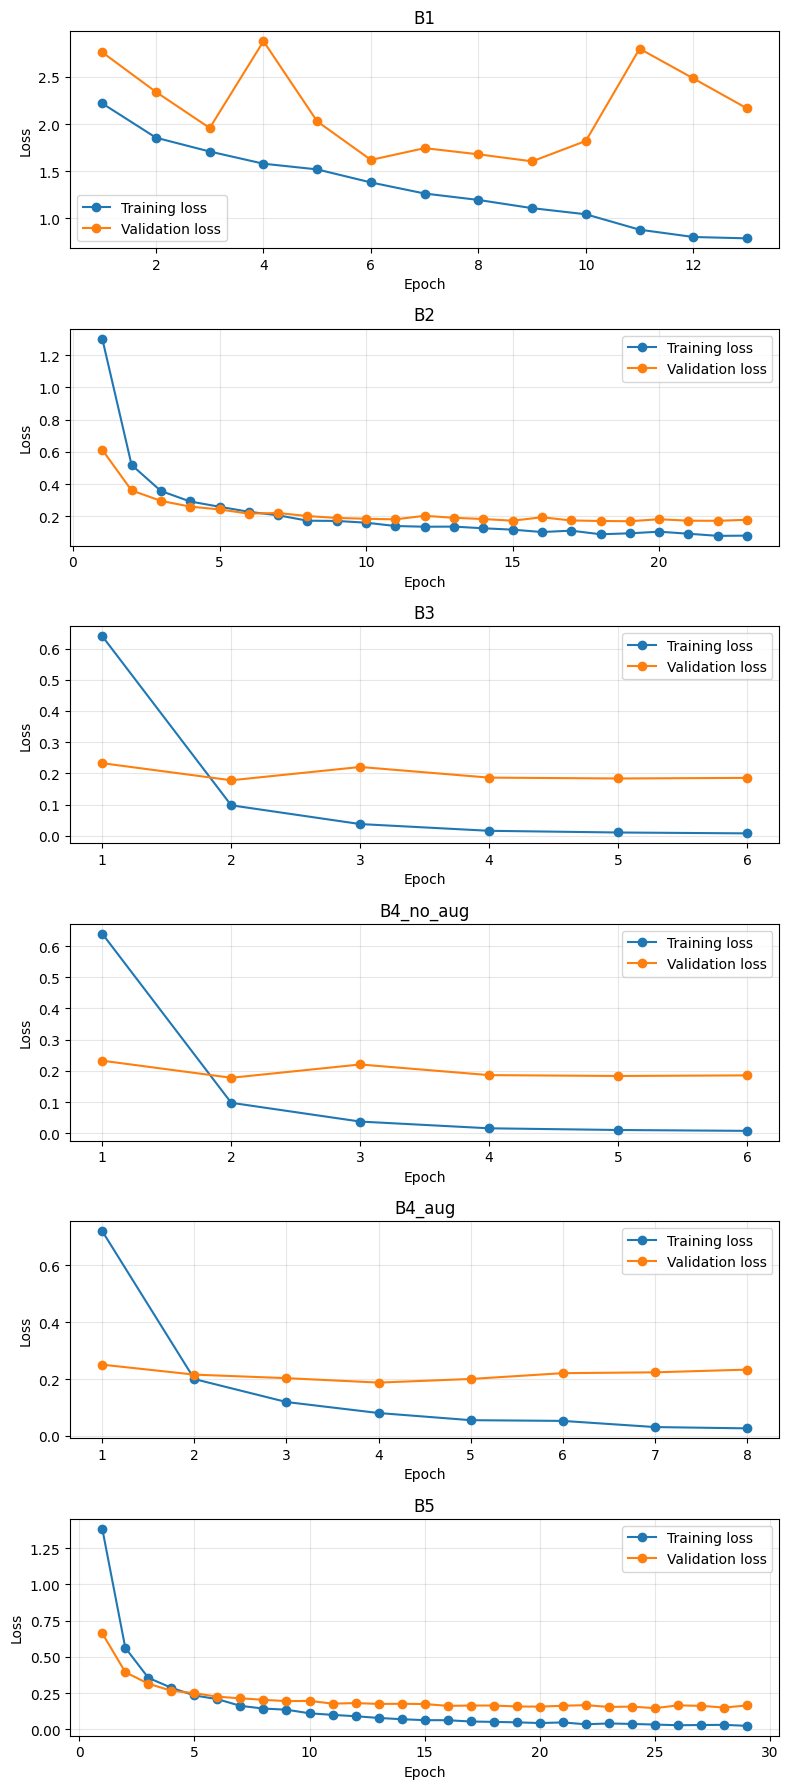

In [68]:
experiment_order = [
    "B1",
    "B2",
    "B3",
    "B4_no_aug",
    "B4_aug",
    "B5",
]

fig, axes = plt.subplots(
    len(experiment_order), 1,
    figsize=(8, 18)
)

for ax, name in zip(axes, experiment_order):
    run_df = pd.DataFrame(all_histories[name])

    ax.plot(
        run_df["epoch"], run_df["train_loss"],
        marker="o", label="Training loss"
    )
    ax.plot(
        run_df["epoch"], run_df["validation_loss"],
        marker="o", label="Validation loss"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.tight_layout()
fig.savefig(
    "loss_curves_all_experiments.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [69]:
from google.colab import files

files.download("epoch_logs.csv")
files.download("experiment_summary.csv")
files.download("loss_curves_all_experiments.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Menampilkan test set yang salah diprediksi oleh model terbaik (B5)

In [72]:
class_names = selected_breeds
misclassified = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader_1:
        images = images.to(device)
        probabilities = torch.softmax(model(images), dim=1)
        confidences, predictions = probabilities.max(dim=1)

        for i in range(len(labels)):
            if predictions[i].item() != labels[i].item():
                misclassified.append({
                    "image": images[i].cpu(),
                    "actual": labels[i].item(),
                    "predicted": predictions[i].item(),
                    "confidence": confidences[i].item(),
                })

                if len(misclassified) == 8:
                    break

        if len(misclassified) == 8:
            break

print(f"Kesalahan terdeteksi: {len(misclassified)}")

Kesalahan terdeteksi: 8


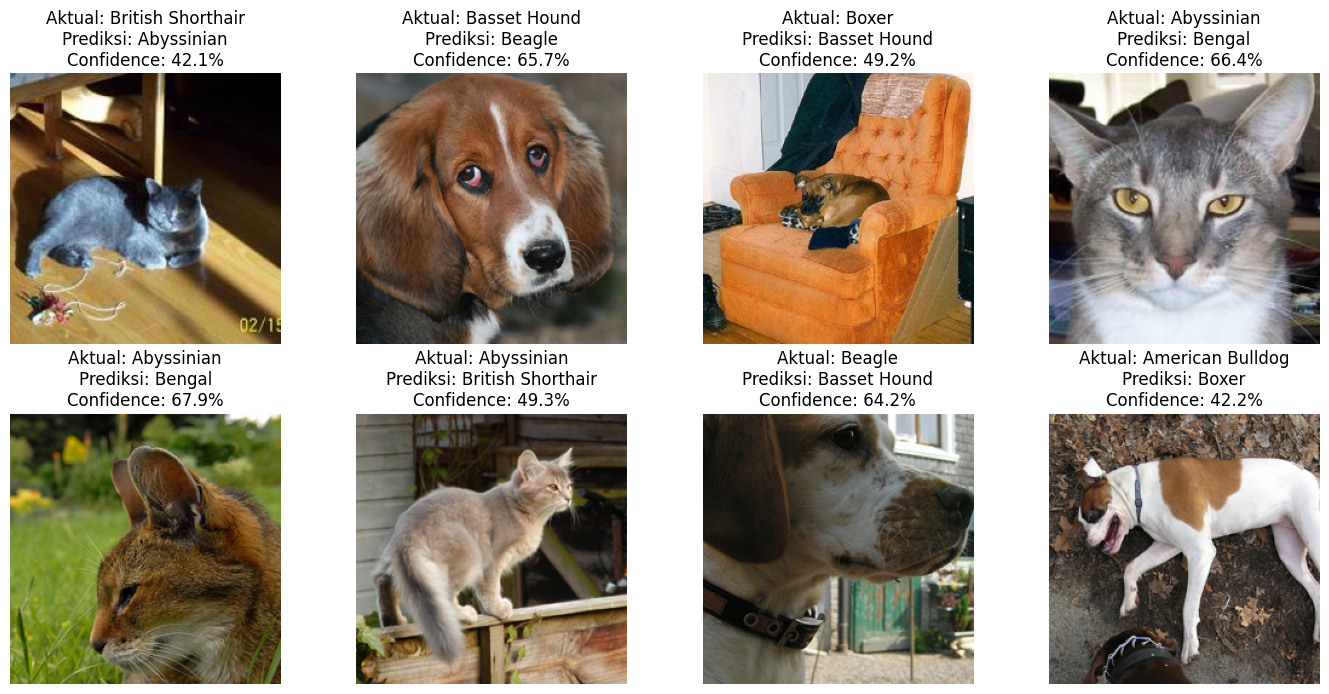

In [71]:
mean = torch.tensor(eff_weights.transforms().mean).view(3, 1, 1)
std = torch.tensor(eff_weights.transforms().std).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax, item in zip(axes, misclassified):
    image = (item["image"] * std + mean).clamp(0, 1)
    image = image.permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(
        f"Aktual: {class_names[item['actual']]}\n"
        f"Prediksi: {class_names[item['predicted']]}\n"
        f"Confidence: {item['confidence']:.1%}"
    )
    ax.axis("off")

for ax in axes[len(misclassified):]:
    ax.axis("off")

fig.tight_layout()
plt.savefig("C3_misklasifikasi_B5.png", dpi=200, bbox_inches="tight")
plt.show()

# C5

In [73]:
import os
print(os.path.exists("B3_best.pth"))

True


In [74]:
# Model pretrained sebelum fine-tuning
model_before = models.resnet18(weights=weights)
model_before = model_before.to(device)
model_before.eval()

# Model setelah fine-tuning B3
model_after = models.resnet18(weights=None)
model_after.fc = nn.Linear(model_after.fc.in_features, 10)

state_dict = torch.load(
    "B3_best.pth",
    map_location=device,
    weights_only=True,
)
model_after.load_state_dict(state_dict)
model_after = model_after.to(device)
model_after.eval()

# Ambil satu gambar test; kedua model akan melihat gambar yang sama
image_batch, label_batch = next(iter(test_loader))
image = image_batch[0:1].to(device)

print("Label angka gambar yang dipilih:", label_batch[0].item())
print("Bentuk input:", image.shape)

Label angka gambar yang dipilih: 1
Bentuk input: torch.Size([1, 3, 224, 224])


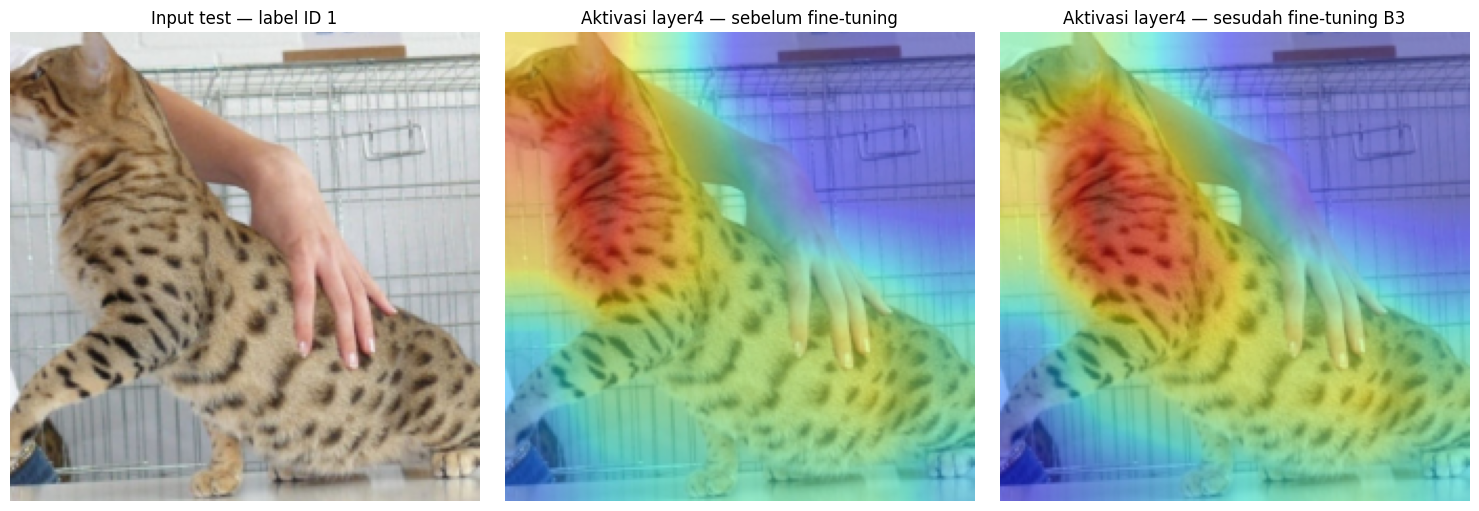

In [77]:
import torch.nn.functional as F

# Ambil aktivasi layer4 sebelum fine-tuning
activations_before = {}
hook_before = model_before.layer4.register_forward_hook(
    lambda module, inputs, output:
        activations_before.update({"layer4": output.detach()})
)

with torch.no_grad():
    model_before(image)

hook_before.remove()

# Ambil aktivasi layer4 sesudah fine-tuning
activations_after = {}
hook_after = model_after.layer4.register_forward_hook(
    lambda module, inputs, output:
        activations_after.update({"layer4": output.detach()})
)

with torch.no_grad():
    model_after(image)

hook_after.remove()

# Rata-ratakan besar aktivasi 512 channel, lalu ubah ukurannya menjadi 224×224
map_before = activations_before["layer4"].abs().mean(dim=1, keepdim=True)
map_before = F.interpolate(
    map_before, size=(224, 224), mode="bilinear", align_corners=False
)[0, 0].cpu()

map_after = activations_after["layer4"].abs().mean(dim=1, keepdim=True)
map_after = F.interpolate(
    map_after, size=(224, 224), mode="bilinear", align_corners=False
)[0, 0].cpu()

# Normalisasi peta agar intensitas warna terlihat
map_before = (map_before - map_before.min()) / (
    map_before.max() - map_before.min() + 1e-8
)
map_after = (map_after - map_after.min()) / (
    map_after.max() - map_after.min() + 1e-8
)

# Tampilkan gambar dalam bentuk RGB tanpa normalisasi ImageNet
mean = torch.tensor(weights.transforms().mean).view(3, 1, 1)
std = torch.tensor(weights.transforms().std).view(3, 1, 1)
image_rgb = (image[0].cpu() * std + mean).clamp(0, 1).permute(1, 2, 0)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_rgb)
axes[0].set_title(f"Input test — label ID {label_batch[0].item()}")

axes[1].imshow(image_rgb)
axes[1].imshow(map_before, cmap="jet", alpha=0.45)
axes[1].set_title("Aktivasi layer4 — sebelum fine-tuning")

axes[2].imshow(image_rgb)
axes[2].imshow(map_after, cmap="jet", alpha=0.45)
axes[2].set_title("Aktivasi layer4 — sesudah fine-tuning B3")

for ax in axes:
    ax.axis("off")

fig.tight_layout()
fig.savefig("C5_layer4_activation_B3.png", dpi=200, bbox_inches="tight")
plt.show()